# Proyek Analisis Data: E-Commerce Public Dataset

## Pendahuluan

Proyek ini bertujuan untuk menganalisis data transaksi e-commerce guna memperoleh informasi mengenai tren pesanan, performa kategori produk, serta perilaku pelanggan berdasarkan metode pembayaran dan skor ulasan.

Analisis dilakukan menggunakan E-Commerce Public Dataset yang terdiri dari beberapa tabel, antara lain data pesanan, pembayaran, item pesanan, produk, dan ulasan pelanggan.

## Pertanyaan Bisnis

1. Bagaimana jumlah pesanan dan total nilai pembayaran berubah dari waktu ke waktu?
2. Kategori produk apa yang memiliki jumlah item terjual dan total nilai penjualan tertinggi?
3. Bagaimana distribusi metode pembayaran dan skor ulasan pelanggan?

In [2]:
import os
import pandas as pd

DATA_PATH = r"A:\ASAH DICODING\submission\data"

if os.path.exists(DATA_PATH):
    print("Folder dataset berhasil ditemukan!")

    csv_files = [
        file for file in os.listdir(DATA_PATH)
        if file.endswith(".csv")
    ]

    print(f"Jumlah file CSV: {len(csv_files)}")

    for file in sorted(csv_files):
        print(file)
else:
    print("Folder dataset tidak ditemukan.")

Folder dataset berhasil ditemukan!
Jumlah file CSV: 9
customers_dataset.csv
geolocation_dataset.csv
order_items_dataset.csv
order_payments_dataset.csv
order_reviews_dataset.csv
orders_dataset.csv
product_category_name_translation.csv
products_dataset.csv
sellers_dataset.csv


In [3]:
import os

DATA_PATH = r"A:\ASAH DICODING\submission\data"

print("Folder data ditemukan:", os.path.exists(DATA_PATH))

csv_files = [
    file for file in os.listdir(DATA_PATH)
    if file.lower().endswith(".csv")
]

print("Jumlah file CSV:", len(csv_files))
print("\nDaftar file:")

for file in sorted(csv_files):
    print("-", file)

Folder data ditemukan: True
Jumlah file CSV: 9

Daftar file:
- customers_dataset.csv
- geolocation_dataset.csv
- order_items_dataset.csv
- order_payments_dataset.csv
- order_reviews_dataset.csv
- orders_dataset.csv
- product_category_name_translation.csv
- products_dataset.csv
- sellers_dataset.csv


In [4]:
import pandas as pd
import os

# Lokasi folder dataset
DATA_PATH = r"A:\ASAH DICODING\submission\data"

# Membaca seluruh dataset
customers_df = pd.read_csv(os.path.join(DATA_PATH, "customers_dataset.csv"))
geolocation_df = pd.read_csv(os.path.join(DATA_PATH, "geolocation_dataset.csv"))
order_items_df = pd.read_csv(os.path.join(DATA_PATH, "order_items_dataset.csv"))
order_payments_df = pd.read_csv(os.path.join(DATA_PATH, "order_payments_dataset.csv"))
order_reviews_df = pd.read_csv(os.path.join(DATA_PATH, "order_reviews_dataset.csv"))
orders_df = pd.read_csv(os.path.join(DATA_PATH, "orders_dataset.csv"))
product_category_df = pd.read_csv(os.path.join(DATA_PATH, "product_category_name_translation.csv"))
products_df = pd.read_csv(os.path.join(DATA_PATH, "products_dataset.csv"))
sellers_df = pd.read_csv(os.path.join(DATA_PATH, "sellers_dataset.csv"))

print("Seluruh dataset berhasil dimuat!")

Seluruh dataset berhasil dimuat!


In [5]:
# Menyimpan seluruh DataFrame dalam dictionary
dataframes = {
    "Customers": customers_df,
    "Geolocation": geolocation_df,
    "Order Items": order_items_df,
    "Order Payments": order_payments_df,
    "Order Reviews": order_reviews_df,
    "Orders": orders_df,
    "Product Category": product_category_df,
    "Products": products_df,
    "Sellers": sellers_df
}

# Menampilkan jumlah baris dan kolom
for name, df in dataframes.items():
    print(f"{name}: {df.shape[0]:,} baris, {df.shape[1]} kolom")

Customers: 99,441 baris, 5 kolom
Geolocation: 1,000,163 baris, 5 kolom
Order Items: 112,650 baris, 7 kolom
Order Payments: 103,886 baris, 5 kolom
Order Reviews: 99,224 baris, 7 kolom
Orders: 99,441 baris, 8 kolom
Product Category: 71 baris, 2 kolom
Products: 32,951 baris, 9 kolom
Sellers: 3,095 baris, 4 kolom


In [6]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
for name, df in dataframes.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name}")
    print("=" * 60)
    df.info()


DATASET: Customers
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB

DATASET: Geolocation
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 n

In [9]:
for name, df in dataframes.items():
    print(f"\n{name}")
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if missing.empty:
        print("Tidak ditemukan missing values.")
    else:
        print(missing.sort_values(ascending=False))


Customers
Tidak ditemukan missing values.

Geolocation
Tidak ditemukan missing values.

Order Items
Tidak ditemukan missing values.

Order Payments
Tidak ditemukan missing values.

Order Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Orders
order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
dtype: int64

Product Category
Tidak ditemukan missing values.

Products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Sellers
Tidak ditemukan missing values.


In [10]:
for name, df in dataframes.items():
    duplicate_count = df.duplicated().sum()
    print(f"{name}: {duplicate_count:,} baris duplikat")

Customers: 0 baris duplikat
Geolocation: 261,831 baris duplikat
Order Items: 0 baris duplikat
Order Payments: 0 baris duplikat
Order Reviews: 0 baris duplikat
Orders: 0 baris duplikat
Product Category: 0 baris duplikat
Products: 0 baris duplikat
Sellers: 0 baris duplikat


In [11]:
for name, df in dataframes.items():
    print(f"\n{'=' * 60}")
    print(f"STATISTIK: {name}")
    print("=" * 60)
    display(df.describe(include="all").T)


STATISTIK: Customers


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,99441,99441,06b8999e2fba1a1fbc88172c00ba8bc7,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_unique_id,99441,96096,8d50f5eadf50201ccdcedfb9e2ac8455,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_zip_code_prefix,99441.0,NaN,NaN,NaN,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0
customer_city,99441,4119,sao paulo,15540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_state,99441,27,SP,41746,NaN,NaN,NaN,NaN,NaN,NaN,NaN



STATISTIK: Geolocation


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,NaN,NaN,NaN,36574.166466,30549.33571,1001.0,11075.0,26530.0,63504.0,99990.0
geolocation_lat,1000163.0,NaN,NaN,NaN,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.97962,45.065933
geolocation_lng,1000163.0,NaN,NaN,NaN,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394
geolocation_city,1000163,8011,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN



STATISTIK: Order Items


...

,count,unique,top,freq
product_category_name,71,71,beleza_saude,1
product_category_name_english,71,71,health_beauty,1



STATISTIK: Products


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,32951,32951,1e9e8ef04dbcff4541ed26657ea517e5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,32341,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name_lenght,32341.0,NaN,NaN,NaN,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,NaN,NaN,NaN,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,NaN,NaN,NaN,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,NaN,NaN,NaN,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,NaN,NaN,NaN,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,NaN,NaN,NaN,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,NaN,NaN,NaN,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0



STATISTIK: Sellers


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
seller_id,3095,3095,3442f8959a84dea7ee197c632cb2df15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_zip_code_prefix,3095.0,NaN,NaN,NaN,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0
seller_city,3095,611,sao paulo,694,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_state,3095,23,SP,1849,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
for name, df in dataframes.items():
    missing_count = df.isnull().sum()
    missing_count = missing_count[missing_count > 0]

    if not missing_count.empty:
        missing_percentage = (
            missing_count / len(df) * 100
        ).round(2)

        print(f"\n{name}")
        print(pd.DataFrame({
            "Missing Values": missing_count,
            "Persentase (%)": missing_percentage
        }))


Order Reviews
                        Missing Values  Persentase (%)
review_comment_title             87656           88.34
review_comment_message           58247           58.70

Orders
                               Missing Values  Persentase (%)
order_approved_at                         160            0.16
order_delivered_carrier_date             1783            1.79
order_delivered_customer_date            2965            2.98

Products
                            Missing Values  Persentase (%)
product_category_name                  610            1.85
product_name_lenght                    610            1.85
product_description_lenght             610            1.85
product_photos_qty                     610            1.85
product_weight_g                         2            0.01
product_length_cm                        2            0.01
product_height_cm                        2            0.01
product_width_cm                         2            0.01


In [13]:
orders_df.loc[
    orders_df["order_delivered_customer_date"].isna(),
    "order_status"
].value_counts(dropna=False)

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [14]:
products_df[products_df.isnull().any(axis=1)].head(10)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [15]:
products_df[
    products_df["product_weight_g"].isnull()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# Menghitung jumlah missing values pada setiap baris
products_df["missing_count"] = products_df.isnull().sum(axis=1)

# Melihat jumlah produk berdasarkan banyaknya missing values
products_df["missing_count"].value_counts().sort_index()

missing_count
0    32340
4      610
8        1
Name: count, dtype: int64

In [17]:
# Melihat produk yang memiliki 5 atau lebih nilai kosong
products_df[products_df["missing_count"] >= 5]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,missing_count
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8


In [18]:
# Simpan jumlah data sebelum cleaning
print("Jumlah data sebelum cleaning:", len(products_df))

# Hapus kolom pemeriksaan sementara
products_df.drop(columns=["missing_count"], inplace=True)

# Hapus produk yang seluruh kolom informasinya kosong
products_df.dropna(
    subset=[
        "product_category_name",
        "product_name_lenght",
        "product_description_lenght",
        "product_photos_qty",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ],
    how="all",
    inplace=True
)

print("Jumlah data setelah cleaning:", len(products_df))
print("Sisa missing values:")
print(products_df.isnull().sum())

Jumlah data sebelum cleaning: 32951
Jumlah data setelah cleaning: 32950
Sisa missing values:
product_id                      0
product_category_name         609
product_name_lenght           609
product_description_lenght    609
product_photos_qty            609
product_weight_g                1
product_length_cm               1
product_height_cm               1
product_width_cm                1
dtype: int64


In [19]:
# Ambil produk yang kategori dan informasi deskripsinya kosong
missing_products = products_df[
    products_df["product_category_name"].isna()
]

# Periksa apakah produk tersebut muncul dalam transaksi
product_sales = order_items_df[
    order_items_df["product_id"].isin(
        missing_products["product_id"]
    )
]

print("Jumlah produk dengan informasi kosong:", len(missing_products))
print("Jumlah produk yang pernah muncul dalam transaksi:",
      product_sales["product_id"].nunique())
print("Jumlah baris transaksi terkait:", len(product_sales))

Jumlah produk dengan informasi kosong: 609
Jumlah produk yang pernah muncul dalam transaksi: 609
Jumlah baris transaksi terkait: 1586


In [20]:
# Isi kategori produk yang kosong
products_df["product_category_name"] = (
    products_df["product_category_name"].fillna("Unknown")
)

# Periksa sisa missing values
print(products_df.isnull().sum())

product_id                      0
product_category_name           0
product_name_lenght           609
product_description_lenght    609
product_photos_qty            609
product_weight_g                1
product_length_cm               1
product_height_cm               1
product_width_cm                1
dtype: int64


In [21]:
# Periksa status pesanan yang tanggal persetujuan kosong
print("Tanggal persetujuan kosong:")
print(
    orders_df.loc[
        orders_df["order_approved_at"].isna(),
        "order_status"
    ].value_counts()
)

# Periksa status pesanan yang tanggal pengiriman ke kurir kosong
print("\nTanggal pengiriman ke kurir kosong:")
print(
    orders_df.loc[
        orders_df["order_delivered_carrier_date"].isna(),
        "order_status"
    ].value_counts()
)

# Periksa status pesanan yang tanggal diterima pelanggan kosong
print("\nTanggal diterima pelanggan kosong:")
print(
    orders_df.loc[
        orders_df["order_delivered_customer_date"].isna(),
        "order_status"
    ].value_counts()
)

Tanggal persetujuan kosong:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Tanggal pengiriman ke kurir kosong:
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Tanggal diterima pelanggan kosong:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [22]:
# Pesanan delivered dengan tanggal pengiriman yang tidak lengkap
incomplete_delivered = orders_df[
    (orders_df["order_status"] == "delivered") &
    (
        orders_df["order_delivered_carrier_date"].isna() |
        orders_df["order_delivered_customer_date"].isna()
    )
]

incomplete_delivered[
    [
        "order_id",
        "order_status",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
]

,order_id,order_status,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN
73222,2aa91108853cecb43c84a5dc5b277475,delivered,2017-09-29 09:07:16,NaN,2017-11-20 19:44:47
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:30:16,NaN,NaN
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN


In [23]:
print("Missing values pada Orders:")
print(orders_df.isnull().sum())

print("\nJumlah baris Orders:", len(orders_df))

Missing values pada Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Jumlah baris Orders: 99441


In [24]:
# Melihat beberapa baris duplikat
geolocation_df[
    geolocation_df.duplicated(keep=False)
].sort_values(
    by=[
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng"
    ]
).head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
519,1001,-23.551337,-46.634027,sao paulo,SP
583,1001,-23.551337,-46.634027,sao paulo,SP
818,1001,-23.551337,-46.634027,sao paulo,SP
206,1001,-23.550498,-46.634338,sao paulo,SP
429,1001,-23.550498,-46.634338,sao paulo,SP
596,1001,-23.550498,-46.634338,sao paulo,SP
639,1001,-23.550498,-46.634338,sao paulo,SP
771,1001,-23.550498,-46.634338,sao paulo,SP
912,1001,-23.550498,-46.634338,sao paulo,SP
985,1001,-23.550498,-46.634338,sao paulo,SP


In [25]:
print(
    "Duplikat seluruh kolom:",
    geolocation_df.duplicated().sum()
)

print(
    "Duplikat kode pos dan koordinat:",
    geolocation_df.duplicated(
        subset=[
            "geolocation_zip_code_prefix",
            "geolocation_lat",
            "geolocation_lng"
        ]
    ).sum()
)

Duplikat seluruh kolom: 261831
Duplikat kode pos dan koordinat: 280009


In [26]:
# Cari kombinasi kode pos dan koordinat yang berulang
geo_duplicate = geolocation_df[
    geolocation_df.duplicated(
        subset=[
            "geolocation_zip_code_prefix",
            "geolocation_lat",
            "geolocation_lng"
        ],
        keep=False
    )
]

# Periksa apakah kombinasi tersebut memiliki kota atau negara bagian berbeda
geo_duplicate.groupby(
    [
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng"
    ]
).agg(
    jumlah_kota=("geolocation_city", "nunique"),
    jumlah_state=("geolocation_state", "nunique"),
    contoh_kota=("geolocation_city", "first"),
    contoh_state=("geolocation_state", "first")
).sort_values(
    by=["jumlah_kota", "jumlah_state"],
    ascending=False
).head(10)

jumlah_kota  \
geolocation_zip_code_prefix geolocation_lat geolocation_lng                
1307                        -23.556812      -46.657135                 3   
4346                        -23.640365      -46.652122                 3   
4728                        -23.639872      -46.713571                 3   
11623                       -23.767015      -45.741451                 3   
                            -23.764333      -45.720900                 3   
13453                       -22.726246      -47.394446                 3   
13840                       -22.363562      -46.934867                 3   
13842                       -22.389723      -46.927341                 3   
13844                       -22.395575      -46.948334                 3   
                            -22.380109      -46.947108                 3   

                                                             jumlah_state  \
geolocation_zip_code_prefix geolocation_lat geolocation_lng                 
1307                        -23.556812      -46.657135                  1   
4346                        -23.640365      -46.652122                  1   
4728                        -23.639872      -46.713571                  1   
11623                       -23.767015      -45.741451                  1   
                            -23.764333      -45.720900                  1   
13453                       -22.726246      -47.394446                  1   
13840                       -22.363562      -46.934867                  1   
13842                       -22.389723      -46.927341                  1   
13844                       -22.395575      -46.948334                  1   
                            -22.380109      -46.947108                  1   

                                                                       contoh_kota  \
geolocation_zip_code_prefix geolocation_lat geolocation_lng                          
1307                        -23.556812      -46.657135                   sao paulo   
4346                        -23.640365      -46.652122                   sao paulo   
4728                        -23.639872      -46.713571                   sao paulo   
11623                       -23.767015      -45.741451                    maresias   
                            -23.764333      -45.720900               são sebastião   
13453                       -22.726246      -47.394446       santa bárbara d'oeste   
13840                       -22.363562      -46.934867                  mogi guacu   
13842                       -22.389723      -46.927341                  mogi guacu   
13844                       -22.395575      -46.948334                  mogi guacu   
                            -22.380109      -46.947108                  mogi-guacu   

                                                            contoh_state  
geolocation_zip_code_prefix geolocation_lat geolocation_lng               
1307                        -23.556812      -46.657135                SP  
4346                        -23.640365      -46.652122                SP  
4728                        -23.639872      -46.713571                SP  
11623                       -23.767015      -45.741451                SP  
                            -23.764333      -45.720900                SP  
13453                       -22.726246      -47.394446                SP  
13840                       -22.363562      -46.934867                SP  
13842                       -22.389723      -46.927341                SP  
13844                       -22.395575      -46.948334                SP  
                            -22.380109      -46.947108                SP

In [27]:
# Catat jumlah data sebelum cleaning
print("Sebelum cleaning:", len(geolocation_df))

# Hapus baris yang identik di semua kolom
geolocation_df.drop_duplicates(inplace=True)

# Periksa hasil cleaning
print("Setelah cleaning:", len(geolocation_df))
print("Sisa duplikat:", geolocation_df.duplicated().sum())

Sebelum cleaning: 1000163
Setelah cleaning: 738332
Sisa duplikat: 0


In [28]:
# Periksa kondisi seluruh dataset
for name, df in dataframes.items():
    print(f"\n=== {name} ===")
    print("Jumlah baris:", len(df))
    print("Duplikat:", df.duplicated().sum())
    print("Total missing values:", df.isnull().sum().sum())


=== Customers ===
Jumlah baris: 99441
Duplikat: 0
Total missing values: 0

=== Geolocation ===
Jumlah baris: 738332
Duplikat: 0
Total missing values: 0

=== Order Items ===
Jumlah baris: 112650
Duplikat: 0
Total missing values: 0

=== Order Payments ===
Jumlah baris: 103886
Duplikat: 0
Total missing values: 0

=== Order Reviews ===
Jumlah baris: 99224
Duplikat: 0
Total missing values: 145903

=== Orders ===
Jumlah baris: 99441
Duplikat: 0
Total missing values: 4908

=== Product Category ===
Jumlah baris: 71
Duplikat: 0
Total missing values: 0

=== Products ===
Jumlah baris: 32950
Duplikat: 0
Total missing values: 1831

=== Sellers ===
Jumlah baris: 3095
Duplikat: 0
Total missing values: 0


In [29]:
# Mengisi komentar kosong dengan string kosong
review_columns = [
    "review_comment_title",
    "review_comment_message"
]

order_reviews_df[review_columns] = (
    order_reviews_df[review_columns].fillna("")
)

# Memeriksa hasil
print("Missing values Order Reviews:")
print(order_reviews_df.isnull().sum())

print("\nJumlah baris:", len(order_reviews_df))

Missing values Order Reviews:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

Jumlah baris: 99224


In [30]:
# Periksa missing values pada Orders berdasarkan status
date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for column in date_columns:
    print(f"\nMissing pada {column}:")
    print(
        orders_df.loc[
            orders_df[column].isna(),
            "order_status"
        ].value_counts()
    )


Missing pada order_approved_at:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Missing pada order_delivered_carrier_date:
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Missing pada order_delivered_customer_date:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [31]:
# Periksa produk dengan berat atau dimensi kosong
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products_df.loc[
    products_df[dimension_columns].isna().any(axis=1),
    ["product_id"] + dimension_columns
]

,product_id,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,NaN,NaN,NaN,NaN


In [32]:
products_df.loc[
    products_df["product_length_cm"].isna(),
    [
        "product_id",
        "product_category_name",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
]

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,NaN,NaN,NaN,NaN


In [33]:
print(
    products_df.loc[
        products_df["product_id"] == "09ff539a621711667c43eba6a3bd8466"
    ].T
)

                                                        8578
product_id                  09ff539a621711667c43eba6a3bd8466
product_category_name                                  bebes
product_name_lenght                                     60.0
product_description_lenght                             865.0
product_photos_qty                                       3.0
product_weight_g                                         NaN
product_length_cm                                        NaN
product_height_cm                                        NaN
product_width_cm                                         NaN


In [34]:
print("Jumlah produk:", len(products_df))

print("\nMissing values:")
print(products_df.isnull().sum())

print("\nJumlah duplikat:", products_df.duplicated().sum())

Jumlah produk: 32950

Missing values:
product_id                      0
product_category_name           0
product_name_lenght           609
product_description_lenght    609
product_photos_qty            609
product_weight_g                1
product_length_cm               1
product_height_cm               1
product_width_cm                1
dtype: int64

Jumlah duplikat: 0


In [35]:
# Mengubah kolom tanggal pembelian menjadi datetime
orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"]
)

# Memeriksa tipe data dan rentang tanggal
print(orders_df["order_purchase_timestamp"].dtype)

print(
    "Tanggal paling awal:",
    orders_df["order_purchase_timestamp"].min()
)

print(
    "Tanggal paling akhir:",
    orders_df["order_purchase_timestamp"].max()
)

datetime64[us]
Tanggal paling awal: 2016-09-04 21:15:19
Tanggal paling akhir: 2018-10-17 17:30:18


# Bagaimana jumlah pesanan dan nilai transaksi berubah dari waktu ke waktu?

In [36]:
# Membuat kolom bulan pembelian
orders_df["purchase_month"] = (
    orders_df["order_purchase_timestamp"].dt.to_period("M")
)

# Menghitung jumlah pesanan unik setiap bulan
monthly_orders = (
    orders_df.groupby("purchase_month")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

# Mengubah periode menjadi string agar mudah ditampilkan
monthly_orders["purchase_month"] = (
    monthly_orders["purchase_month"].astype(str)
)

print(monthly_orders.head(10))

  purchase_month  total_orders
0        2016-09             4
1        2016-10           324
2        2016-12             1
3        2017-01           800
4        2017-02          1780
5        2017-03          2682
6        2017-04          2404
7        2017-05          3700
8        2017-06          3245
9        2017-07          4026


In [37]:
# Menggabungkan data pesanan dengan data pembayaran
orders_payments = orders_df[
    ["order_id", "purchase_month"]
].merge(
    order_payments_df[["order_id", "payment_value"]],
    on="order_id",
    how="inner"
)

# Menghitung total nilai transaksi setiap bulan
monthly_revenue = (
    orders_payments.groupby("purchase_month")["payment_value"]
    .sum()
    .reset_index(name="total_revenue")
)

# Mengubah bulan menjadi string
monthly_revenue["purchase_month"] = (
    monthly_revenue["purchase_month"].astype(str)
)

print(monthly_revenue.head(10))

  purchase_month  total_revenue
0        2016-09         252.24
1        2016-10       59090.48
2        2016-12          19.62
3        2017-01      138488.04
4        2017-02      291908.01
5        2017-03      449863.60
6        2017-04      417788.03
7        2017-05      592918.82
8        2017-06      511276.38
9        2017-07      592382.92


In [38]:
# Menggabungkan jumlah pesanan dan nilai transaksi per bulan
monthly_analysis = monthly_orders.merge(
    monthly_revenue,
    on="purchase_month",
    how="outer"
)

# Mengurutkan data berdasarkan bulan
monthly_analysis = monthly_analysis.sort_values(
    "purchase_month"
).reset_index(drop=True)

print(monthly_analysis.to_string(index=False))

purchase_month  total_orders  total_revenue
       2016-09             4         252.24
       2016-10           324       59090.48
       2016-12             1          19.62
       2017-01           800      138488.04
       2017-02          1780      291908.01
       2017-03          2682      449863.60
       2017-04          2404      417788.03
       2017-05          3700      592918.82
       2017-06          3245      511276.38
       2017-07          4026      592382.92
       2017-08          4331      674396.32
       2017-09          4285      727762.45
       2017-10          4631      779677.88
       2017-11          7544     1194882.80
       2017-12          5673      878401.48
       2018-01          7269     1115004.18
       2018-02          6728      992463.34
       2018-03          7211     1159652.12
       2018-04          6939     1160785.48
       2018-05          6873     1153982.15
       2018-06          6167     1023880.50
       2018-07          6292    

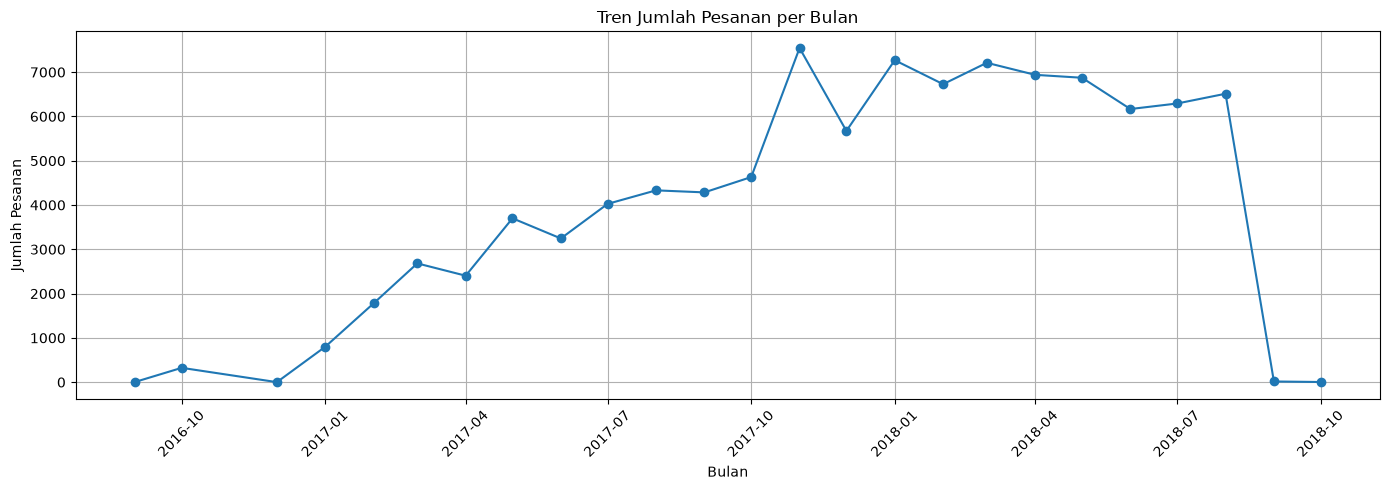

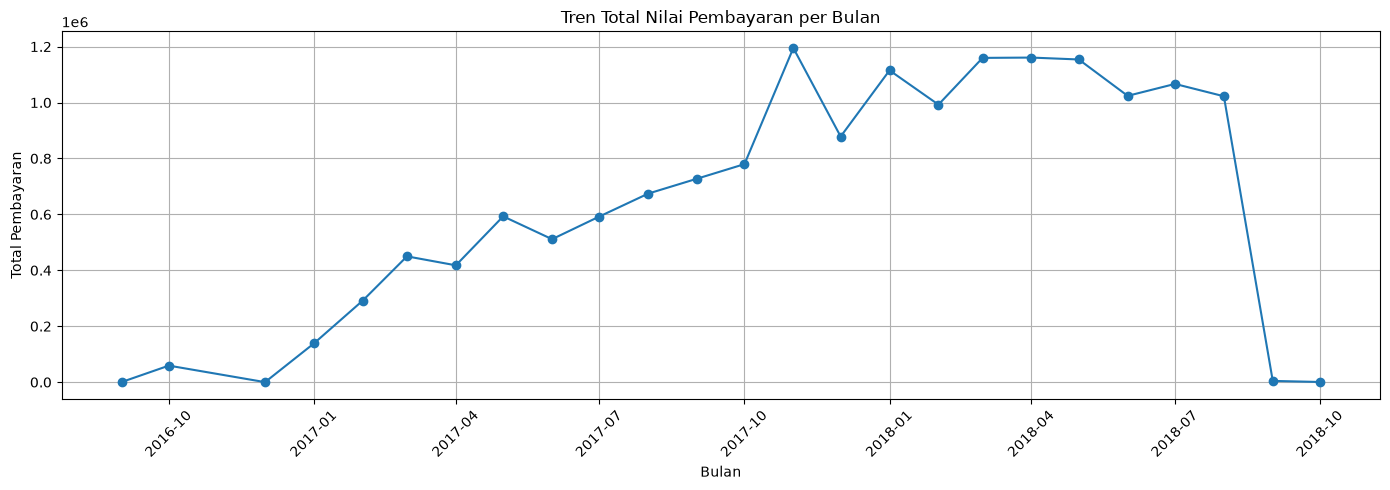

In [39]:
import matplotlib.pyplot as plt

# Mengubah kolom bulan menjadi datetime untuk sumbu grafik
monthly_analysis["purchase_month"] = pd.to_datetime(
    monthly_analysis["purchase_month"]
)

# Grafik jumlah pesanan bulanan
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_analysis["purchase_month"],
    monthly_analysis["total_orders"],
    marker="o"
)
plt.title("Tren Jumlah Pesanan per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Grafik nilai pembayaran bulanan
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_analysis["purchase_month"],
    monthly_analysis["total_revenue"],
    marker="o"
)
plt.title("Tren Total Nilai Pembayaran per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Total Pembayaran")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
# Memilih periode Januari 2017 sampai Agustus 2018
analysis_period = monthly_analysis[
    (monthly_analysis["purchase_month"] >= "2017-01-01") &
    (monthly_analysis["purchase_month"] <= "2018-08-01")
].copy()

# Bulan dengan jumlah pesanan tertinggi
print("Jumlah pesanan tertinggi:")
print(
    analysis_period.loc[
        analysis_period["total_orders"].idxmax()
    ]
)

# Bulan dengan nilai pembayaran tertinggi
print("\nNilai pembayaran tertinggi:")
print(
    analysis_period.loc[
        analysis_period["total_revenue"].idxmax()
    ]
)

Jumlah pesanan tertinggi:
purchase_month    2017-11-01 00:00:00
total_orders                     7544
total_revenue               1194882.8
Name: 13, dtype: object

Nilai pembayaran tertinggi:
purchase_month    2017-11-01 00:00:00
total_orders                     7544
total_revenue               1194882.8
Name: 13, dtype: object


# Kategori produk apa yang memiliki penjualan tertinggi?

In [41]:
# Menggabungkan data transaksi dengan informasi produk
category_sales = order_items_df.merge(
    products_df[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Menerjemahkan nama kategori ke bahasa Inggris
category_sales = category_sales.merge(
    product_category_df,
    on="product_category_name",
    how="left"
)

# Periksa hasil penggabungan
print("Jumlah baris:", len(category_sales))
print(category_sales.head())

Jumlah baris: 112650
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value product_category_name  \
0  2017-09-19 09:45:35   58.90          13.29            cool_stuff   
1  2017-05-03 11:05:13  239.90          19.93              pet_shop   
2 

In [42]:
# Menghitung jumlah item terjual per kategori
top_categories_quantity = (
    category_sales.groupby("product_category_name_english")["order_item_id"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="total_items_sold")
)

print(top_categories_quantity.head(10))

  product_category_name_english  total_items_sold
0                bed_bath_table             11115
1                 health_beauty              9670
2                sports_leisure              8641
3               furniture_decor              8334
4         computers_accessories              7827
5                    housewares              6964
6                 watches_gifts              5991
7                     telephony              4545
8                  garden_tools              4347
9                          auto              4235


In [43]:
# Menghitung total nilai produk terjual per kategori
top_categories_revenue = (
    category_sales.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="total_sales")
)

print(top_categories_revenue.head(10))

  product_category_name_english  total_sales
0                 health_beauty   1258681.34
1                 watches_gifts   1205005.68
2                bed_bath_table   1036988.68
3                sports_leisure    988048.97
4         computers_accessories    911954.32
5               furniture_decor    729762.49
6                    cool_stuff    635290.85
7                    housewares    632248.66
8                          auto    592720.11
9                  garden_tools    485256.46


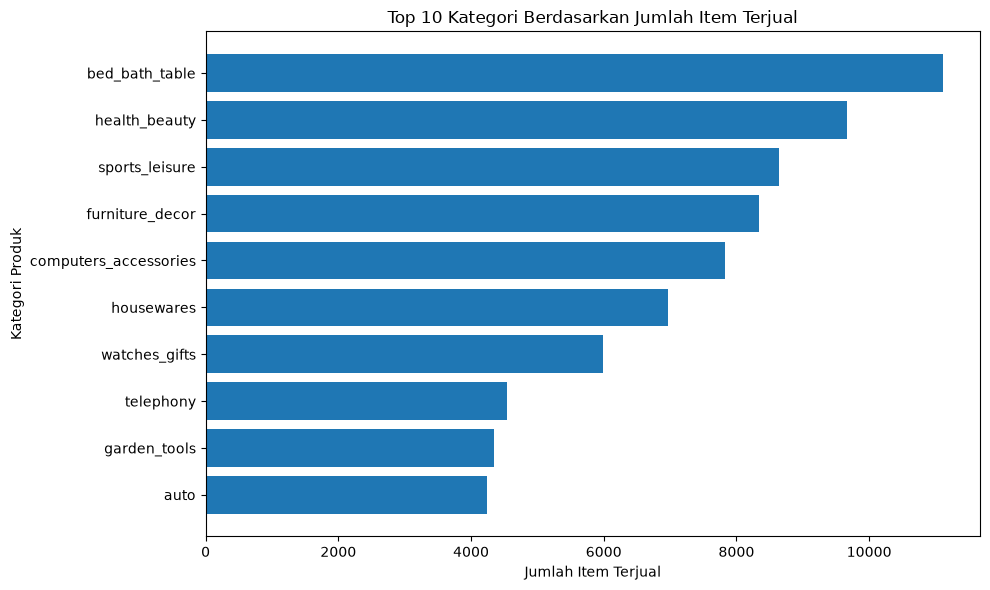

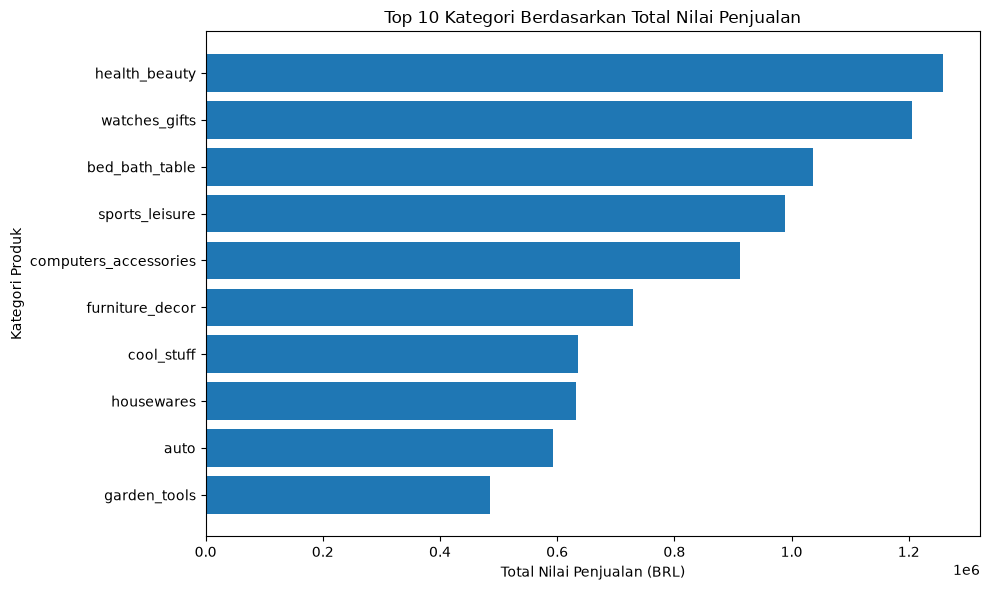

In [44]:
import matplotlib.pyplot as plt

# 10 kategori dengan item terjual terbanyak
top_quantity = top_categories_quantity.head(10).sort_values(
    "total_items_sold"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_quantity["product_category_name_english"],
    top_quantity["total_items_sold"]
)
plt.title("Top 10 Kategori Berdasarkan Jumlah Item Terjual")
plt.xlabel("Jumlah Item Terjual")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()


# 10 kategori dengan nilai penjualan tertinggi
top_revenue = top_categories_revenue.head(10).sort_values(
    "total_sales"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_revenue["product_category_name_english"],
    top_revenue["total_sales"]
)
plt.title("Top 10 Kategori Berdasarkan Total Nilai Penjualan")
plt.xlabel("Total Nilai Penjualan (BRL)")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

### Kesimpulan EDA: Kategori Produk dengan Penjualan Tertinggi

Berdasarkan hasil analisis terhadap dataset E-Commerce Public Dataset, kategori `bed_bath_table` memiliki jumlah item terjual tertinggi, yaitu sebanyak 11.115 item. Sementara itu, kategori `health_beauty` mencatat total nilai penjualan tertinggi sebesar BRL 1.258.681,34, diikuti oleh `watches_gifts` sebesar BRL 1.205.005,68.

Hasil ini menunjukkan bahwa kategori dengan jumlah item terjual terbanyak tidak selalu memiliki total nilai penjualan terbesar. Oleh karena itu, evaluasi performa kategori produk sebaiknya mempertimbangkan jumlah item terjual dan total nilai penjualan secara bersamaan.

Sebagai rekomendasi awal, bisnis dapat mempertahankan ketersediaan produk pada kategori dengan volume penjualan tinggi serta mengevaluasi strategi pemasaran untuk kategori dengan nilai penjualan tinggi. Keputusan terkait stok dan promosi sebaiknya mempertimbangkan informasi tambahan seperti harga rata-rata, margin keuntungan, dan tren penjualan dari waktu ke waktu.

In [45]:
# Menghitung rata-rata harga item per kategori
average_price_category = (
    category_sales.groupby("product_category_name_english")["price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="average_price")
)

# Menampilkan 10 kategori dengan rata-rata harga tertinggi
print(average_price_category.head(10).round(2))

           product_category_name_english  average_price
0                              computers        1098.34
1  small_appliances_home_oven_and_coffee         624.29
2                      home_appliances_2         476.12
3             agro_industry_and_commerce         342.12
4                    musical_instruments         281.62
5                       small_appliances         280.78
6                        fixed_telephony         225.69
7              construction_tools_safety         208.99
8                          watches_gifts         201.14
9                       air_conditioning         185.27


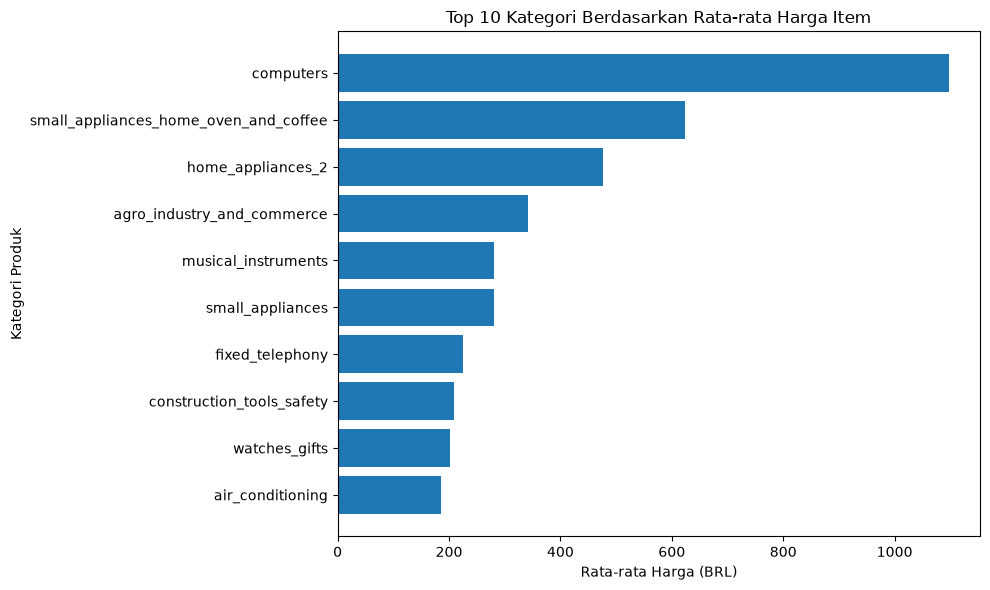

In [46]:
import matplotlib.pyplot as plt

top_average_price = average_price_category.head(10).sort_values(
    "average_price"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_average_price["product_category_name_english"],
    top_average_price["average_price"]
)
plt.title("Top 10 Kategori Berdasarkan Rata-rata Harga Item")
plt.xlabel("Rata-rata Harga (BRL)")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

# Bagaimana distribusi metode pembayaran dan skor ulasan pelanggan?

In [47]:
# Menghitung frekuensi setiap metode pembayaran
payment_counts = (
    order_payments_df["payment_type"]
    .value_counts()
    .reset_index()
)

payment_counts.columns = ["payment_type", "total_transactions"]

print(payment_counts)

  payment_type  total_transactions
0  credit_card               76795
1       boleto               19784
2      voucher                5775
3   debit_card                1529
4  not_defined                   3


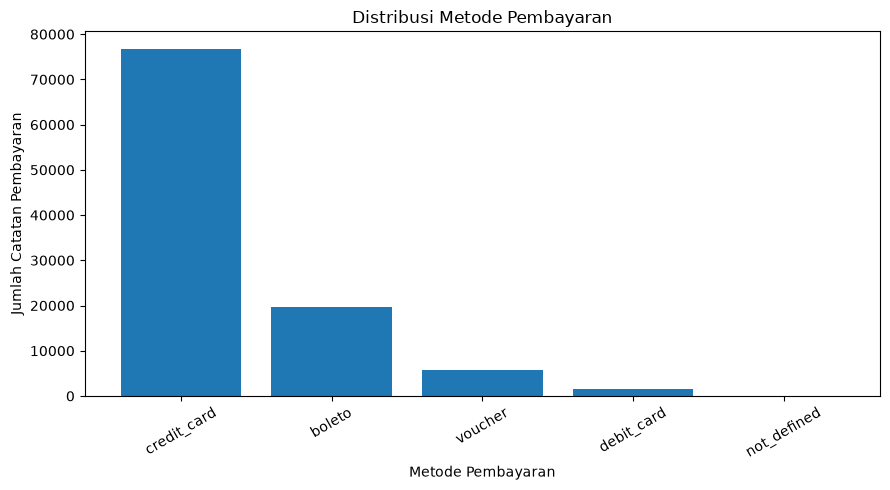

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    payment_counts["payment_type"],
    payment_counts["total_transactions"]
)
plt.title("Distribusi Metode Pembayaran")
plt.xlabel("Metode Pembayaran")
plt.ylabel("Jumlah Catatan Pembayaran")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [49]:
# Menghitung frekuensi setiap skor ulasan
review_counts = (
    order_reviews_df["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_counts.columns = ["review_score", "total_reviews"]

print(review_counts)

   review_score  total_reviews
0             1          11424
1             2           3151
2             3           8179
3             4          19142
4             5          57328


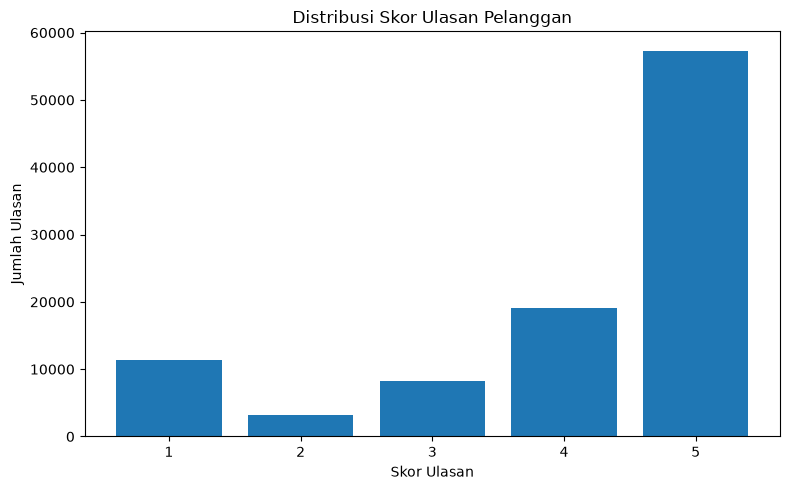

In [50]:
plt.figure(figsize=(8, 5))
plt.bar(
    review_counts["review_score"],
    review_counts["total_reviews"]
)
plt.title("Distribusi Skor Ulasan Pelanggan")
plt.xlabel("Skor Ulasan")
plt.ylabel("Jumlah Ulasan")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

### Kesimpulan EDA: Metode Pembayaran dan Skor Ulasan Pelanggan

Berdasarkan analisis dataset E-Commerce Public Dataset, metode pembayaran yang paling sering tercatat adalah credit card sebanyak 76.795 catatan, diikuti boleto sebanyak 19.784 catatan dan voucher sebanyak 5.775 catatan. Hal ini menunjukkan bahwa credit card merupakan metode pembayaran yang dominan dalam data transaksi yang dianalisis.

Pada distribusi skor ulasan, skor 5 menjadi skor yang paling banyak diberikan, yaitu 57.328 ulasan atau sekitar 57,8% dari total ulasan. Secara keseluruhan, sekitar 77,1% ulasan memiliki skor 4 atau 5, dengan rata-rata skor sekitar 4,09 dari 5.

Hasil tersebut menunjukkan bahwa mayoritas ulasan pelanggan cenderung positif. Meskipun demikian, terdapat 11.424 ulasan dengan skor 1 yang perlu diperhatikan. Bisnis dapat meninjau ulasan bernilai rendah untuk mengidentifikasi area layanan atau proses pemesanan yang perlu diperbaiki.

Analisis ini bersifat deskriptif dan belum membuktikan hubungan sebab-akibat antara metode pembayaran dan kepuasan pelanggan.

# Kesimpulan dan Rekomendasi

## Kesimpulan

Berdasarkan analisis E-Commerce Public Dataset, diperoleh beberapa temuan utama:

1. **Tren pesanan dan pembayaran:** jumlah pesanan dan total nilai pembayaran secara umum meningkat sepanjang 2017. Puncaknya terjadi pada November 2017, dengan 7.544 pesanan dan total nilai pembayaran sebesar BRL 1.194.882,80. Data pada akhir periode perlu ditafsirkan secara hati-hati karena kemungkinan belum lengkap.

2. **Kategori produk:** kategori `bed_bath_table` memiliki jumlah item terjual tertinggi sebanyak 11.115 item, sedangkan `health_beauty` memiliki total nilai penjualan tertinggi sebesar BRL 1.258.681,34. Kategori `computers` memiliki rata-rata harga item tertinggi di antara kategori yang dianalisis, yaitu BRL 1.098,34.

3. **Pembayaran dan ulasan:** credit card menjadi metode pembayaran yang paling sering tercatat, sebanyak 76.795 catatan. Skor ulasan 5 merupakan skor terbanyak, yaitu 57.328 ulasan. Rata-rata skor ulasan sekitar 4,09 dari 5, meskipun terdapat 11.424 ulasan dengan skor 1.

## Rekomendasi

1. Evaluasi faktor yang berkaitan dengan tingginya aktivitas pesanan pada November 2017 untuk membantu perencanaan penjualan pada periode mendatang.
2. Pertahankan ketersediaan produk pada kategori dengan volume penjualan tinggi, serta evaluasi strategi pemasaran untuk kategori dengan total nilai penjualan tinggi.
3. Gunakan jumlah item terjual, total nilai penjualan, dan rata-rata harga secara bersamaan ketika mengevaluasi performa kategori produk.
4. Tinjau ulasan dengan skor rendah untuk menemukan aspek layanan yang perlu diperbaiki.
5. Pastikan kelengkapan data sebelum menarik kesimpulan dari periode dengan jumlah pesanan yang sangat rendah.

Rekomendasi ini merupakan usulan awal berdasarkan analisis deskriptif. Analisis tambahan diperlukan untuk menguji penyebab perubahan penjualan, menghitung keuntungan, atau menentukan faktor yang memengaruhi kepuasan pelanggan.